In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
os.chdir('/content/drive/MyDrive/SV_Thesis/Code/HPV')

In [ ]:
ls

'Copy of SV_thesis_stat.ipynb'  'Data Analysis_V2_HPPV_+ve.csv'


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
data = pd.read_csv("Data Analysis_V2_HPPV_+ve.csv")
print(data.head())

       ID No HPV Status Carcinoma Status  Age  Gender Sexual History Grade  \
0   PGV-24-8   Positive         Positive   46  Female            Yes     1   
1  PGV-24-11   Positive         Positive   66    Male        Unknown     2   
2  PGV-24-14   Positive         Positive   50  Female            Yes     1   
3  PGV-24-16   Positive         Positive   58    Male        Unknown     1   
4  PGV-24-21   Positive         Positive   60  Female        Unknown     1   

  Marital Status Educational Level Occupation  ... Alcohol addict. No addict.  \
0            Yes          Literate  Housewife  ...              No         No   
1            Yes        Illiterate         No  ...              No         No   
2            Yes          Literate  Housewife  ...              No         No   
3            Yes        Illiterate    Laborer  ...              No         No   
4            Yes          Literate  Housewife  ...              No        Yes   

  addict. Data NA Cancer in Family or Relati

File saved at: /content/drive/MyDrive/SV_Thesis/Code/HPV/Carcinoma_Status_Distribution_HPV.png


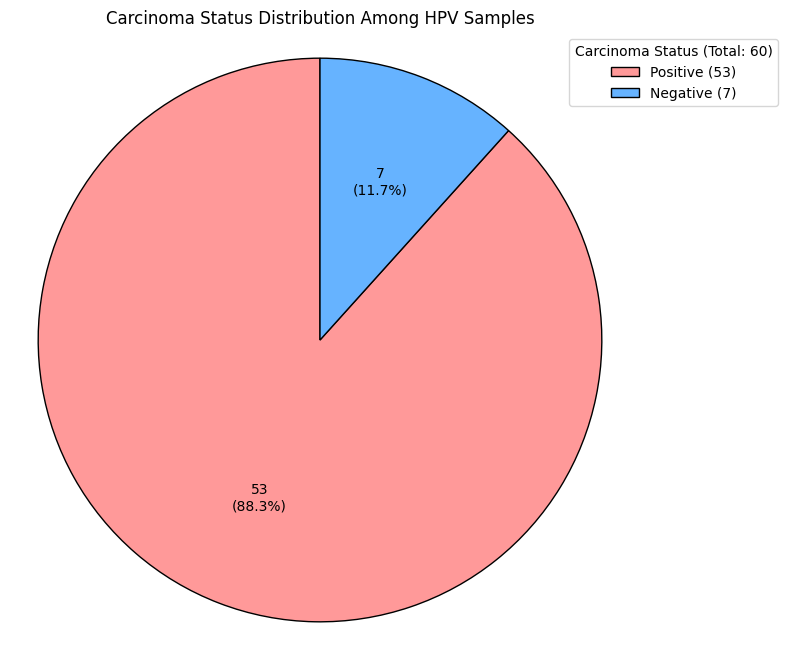

In [ ]:
# Count the carcinoma status distribution
carcinoma_status_counts = data['Carcinoma Status'].value_counts()

# Define custom colors
colors = ['#ff9999', '#66b3ff', '#99ff99', '#ffcc99']
unknown_color = '#d3d3d3'

# Create the figure with a square aspect ratio
plt.figure(figsize=(8, 8))
wedges, texts, autotexts = plt.pie(
    carcinoma_status_counts,
    autopct='',
    startangle=90,
    colors=colors[:len(carcinoma_status_counts)],
    wedgeprops={'edgecolor': 'black'}
)


# Add legend and title
total_samples = carcinoma_status_counts.sum()
legend_labels = [f"{status} ({count})" for status, count in carcinoma_status_counts.items()]
plt.legend(
    wedges,
    legend_labels,
    title=f"Carcinoma Status (Total: {total_samples})",
    loc="upper right",
    bbox_to_anchor=(1.25, 1)
)
plt.title("Carcinoma Status Distribution Among HPV Samples")
plt.axis('equal')  # Ensure pie is drawn as a perfect circle

# Save the chart
output_file = '/content/drive/MyDrive/SV_Thesis/Code/HPV/Carcinoma_Status_Distribution_HPV.png'
plt.savefig(output_file, format='png', dpi=600, bbox_inches='tight')
print(f"File saved at: {output_file}")
plt.show()


File saved at: /content/drive/MyDrive/SV_Thesis/Code/HPV/HPV_Grade_Distribution_Positive_Samples.png


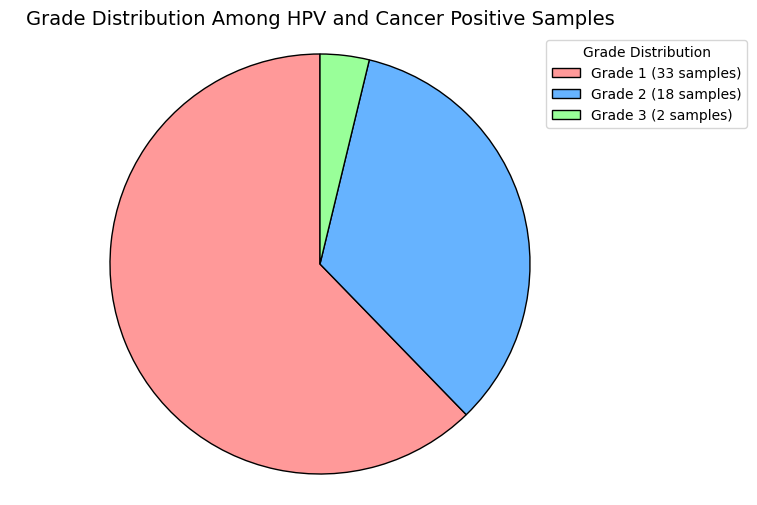

In [ ]:
# Filter for positive samples
positive_samples = data[data['Carcinoma Status'] == 'Positive']

# Count the grade distribution among positive samples
grade_distribution = positive_samples['Grade'].value_counts().sort_index()

# Creating the pie chart with simpler colors, adding sample numbers with percentages, and a legend
plt.figure(figsize=(8, 6))

# Defining simple colors
colors = ['#ff9999', '#66b3ff', '#99ff99', '#ffcc99']

# Plot the pie chart
wedges, texts, autotexts = plt.pie(
    grade_distribution,
    labels=None,  # Disable default labels
    autopct='',  # Disable default percentages
    startangle=90,
    colors=colors[:len(grade_distribution)],
    wedgeprops={'edgecolor': 'black'}
)

# Adding a legend with grade labels and sample numbers
legend_labels = [f"Grade {int(grade)} ({count} samples)" for grade, count in grade_distribution.items()]
plt.legend(
    wedges,
    legend_labels,
    title="Grade Distribution",
    loc="upper right",
    bbox_to_anchor=(1.2, 1)
)

# Adding a title
plt.title("Grade Distribution Among HPV and Cancer Positive Samples", fontsize=14)
plt.axis('equal')  # Equal aspect ratio ensures the pie is drawn as a circle

# Save the chart
# Define the output file path
output_file = '/content/drive/MyDrive/SV_Thesis/Code/HPV/HPV_Grade_Distribution_Positive_Samples.png'
plt.savefig(output_file, format='png', dpi=600, bbox_inches='tight')
print(f"File saved at: {output_file}")
plt.show()

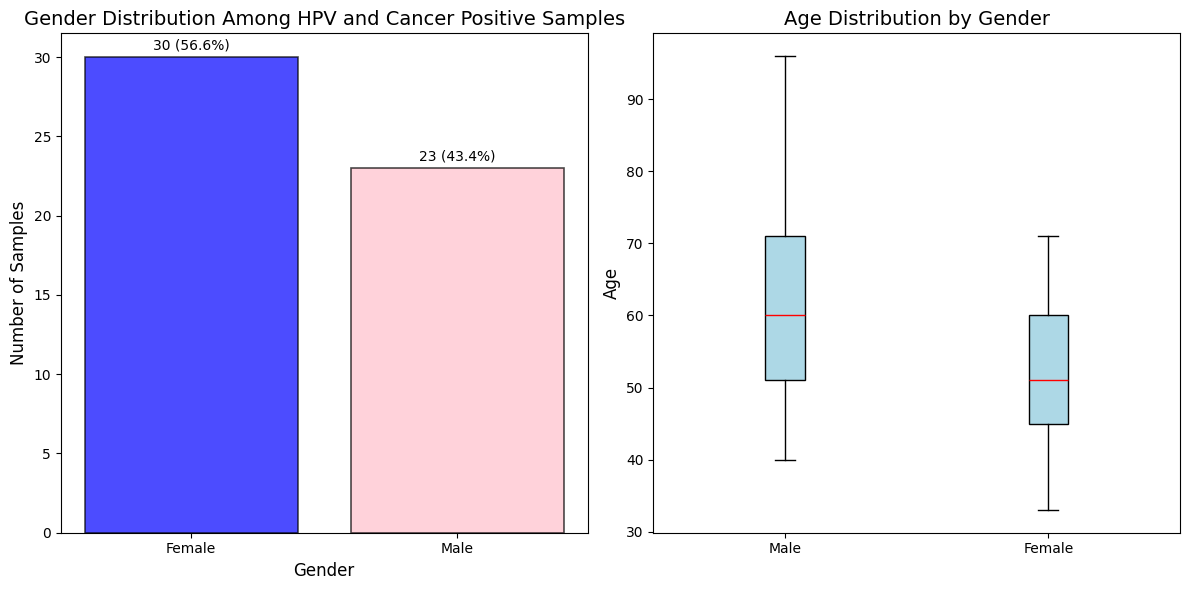

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Replace 'Unknown' or invalid age values with NaN for proper statistical analysis
data['Age'] = pd.to_numeric(data['Age'], errors='coerce')

# Filter for cancer-positive samples
positive_samples = data[data['Carcinoma Status'] == 'Positive']

# Separate the data by gender
male_ages = positive_samples[positive_samples['Gender'] == 'Male']['Age'].dropna()
female_ages = positive_samples[positive_samples['Gender'] == 'Female']['Age'].dropna()

# Descriptive statistics
male_stats = male_ages.describe()
female_stats = female_ages.describe()

# T-test for age distributions
t_stat, p_value = stats.ttest_ind(male_ages, female_ages, equal_var=False)

# Calculate gender distribution percentages and counts
gender_counts = positive_samples['Gender'].value_counts()
total_samples = gender_counts.sum()
gender_percentages = (gender_counts / total_samples) * 100

# Visualization of results
plt.figure(figsize=(12, 6))

# Bar plot for gender percentages
plt.subplot(1, 2, 1)
bars = plt.bar(gender_counts.index, gender_counts, color=['blue', 'pink'], alpha=0.7, edgecolor='black', linewidth=1.2)
for bar, count, pct in zip(bars, gender_counts, gender_percentages):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
             f"{count} ({pct:.1f}%)", ha='center', fontsize=10)
plt.title("Gender Distribution Among HPV and Cancer Positive Samples", fontsize=14)
plt.ylabel("Number of Samples", fontsize=12)
plt.xlabel("Gender", fontsize=12)

# Boxplot for age distribution
plt.subplot(1, 2, 2)
plt.boxplot([male_ages, female_ages], labels=['Male', 'Female'], patch_artist=True,
            boxprops=dict(facecolor='lightblue'), medianprops=dict(color='red'))
plt.title("Age Distribution by Gender", fontsize=14)
plt.ylabel("Age", fontsize=12)

plt.tight_layout()
plt.show()

# Prepare detailed results for display
results_dict = {
    "Male Age Statistics": male_stats,
    "Female Age Statistics": female_stats,
    "T-Test": {"T-Statistic": t_stat, "P-Value": p_value},
    "Gender Distribution": {"Counts": gender_counts, "Percentages": gender_percentages}
}

# Convert statistics to a DataFrame for better visualization
result_df = pd.DataFrame({
    "Statistic": ["Count", "Mean", "Std", "Min", "25%", "50%", "75%", "Max"],
    "Male": male_stats,
    "Female": female_stats
})

# Add T-Test results
result_df = result_df


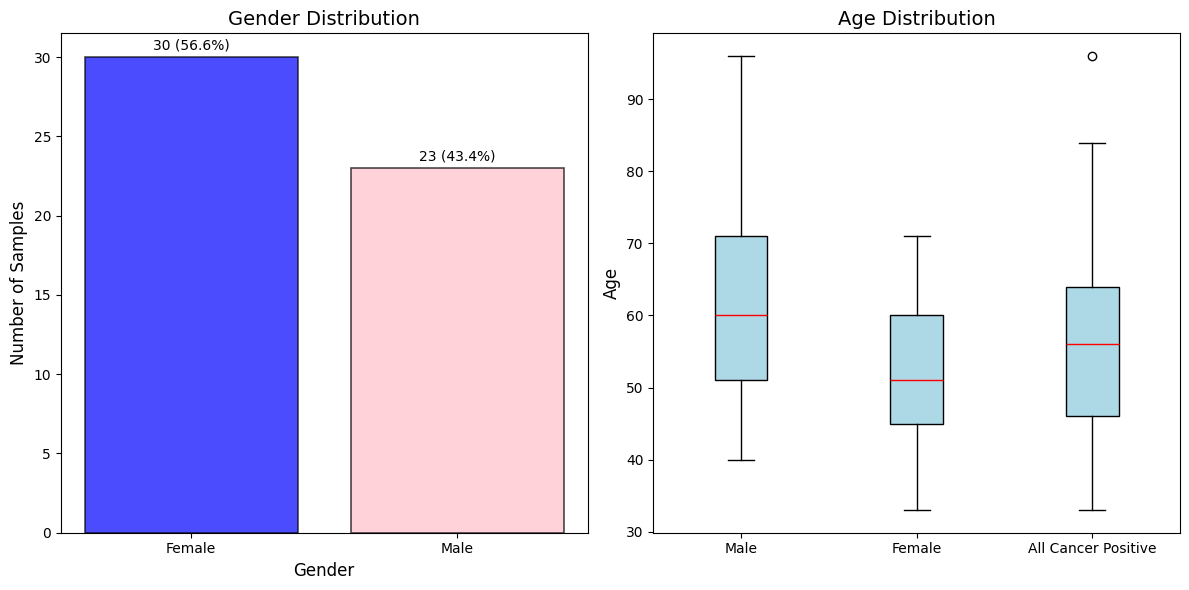

In [ ]:
# Boxplot for age distribution of all cancer positive samples
all_ages = positive_samples['Age'].dropna()

# Visualization of results with added boxplot for all cancer-positive samples
plt.figure(figsize=(12, 6))

# Bar plot for gender percentages
plt.subplot(1, 2, 1)
bars = plt.bar(gender_counts.index, gender_counts, color=['blue', 'pink'], alpha=0.7, edgecolor='black', linewidth=1.2)
for bar, count, pct in zip(bars, gender_counts, gender_percentages):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
             f"{count} ({pct:.1f}%)", ha='center', fontsize=10)
plt.title("Gender Distribution", fontsize=14)
plt.ylabel("Number of Samples", fontsize=12)
plt.xlabel("Gender", fontsize=12)

# Boxplot for age distribution by gender and all samples
plt.subplot(1, 2, 2)
plt.boxplot([male_ages, female_ages, all_ages], labels=['Male', 'Female', 'All Cancer Positive'], patch_artist=True,
            boxprops=dict(facecolor='lightblue'), medianprops=dict(color='red'))
plt.title("Age Distribution", fontsize=14)
plt.ylabel("Age", fontsize=12)

plt.tight_layout()
plt.show()

# Prepare detailed results for display
results_dict = {
    "Male Age Statistics": male_stats,
    "Female Age Statistics": female_stats,
    "T-Test": {"T-Statistic": t_stat, "P-Value": p_value},
    "Gender Distribution": {"Counts": gender_counts, "Percentages": gender_percentages}
}

# Convert statistics to a DataFrame for better visualization
result_df = pd.DataFrame({
    "Statistic": ["Count", "Mean", "Std", "Min", "25%", "50%", "75%", "Max"],
    "Male": male_stats,
    "Female": female_stats
})

# Add T-Test results
result_df = result_df


In [ ]:
# Save the descriptive statistics and T-test results in a CSV file
result_df.to_csv('/content/drive/MyDrive/SV_Thesis/Code/HPV/Age_and_Gender_Analysis.csv', index=False)

# Visualization of results with added boxplot for all cancer-positive samples
plt.figure(figsize=(12, 6))

# Bar plot for gender percentages
plt.subplot(1, 2, 1)
bars = plt.bar(gender_counts.index, gender_counts, color=['blue', 'pink'], alpha=0.7, edgecolor='black', linewidth=1.2)
for bar, count, pct in zip(bars, gender_counts, gender_percentages):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
             f"{count} ({pct:.1f}%)", ha='center', fontsize=10)
plt.title("Gender Distribution", fontsize=14)
plt.ylabel("Number of Samples", fontsize=12)
plt.xlabel("Gender", fontsize=12)

# Boxplot for age distribution by gender and all samples
plt.subplot(1, 2, 2)
plt.boxplot([male_ages, female_ages, all_ages], labels=['Male', 'Female', 'All Cancer Positive'], patch_artist=True,
            boxprops=dict(facecolor='lightblue'), medianprops=dict(color='red'))
plt.title("Age Distribution", fontsize=14)
plt.ylabel("Age", fontsize=12)

# Save the figure
output_plot_path = '/content/drive/MyDrive/SV_Thesis/Code/HPV/Age_and_Gender_Analysis_Plot.png'
plt.tight_layout()
plt.savefig(output_plot_path, format='png', dpi=300)
plt.close()

print(f"Plot saved as PNG: {output_plot_path}")


Plot saved as PNG: /content/drive/MyDrive/SV_Thesis/Code/HPV/Age_and_Gender_Analysis_Plot.png


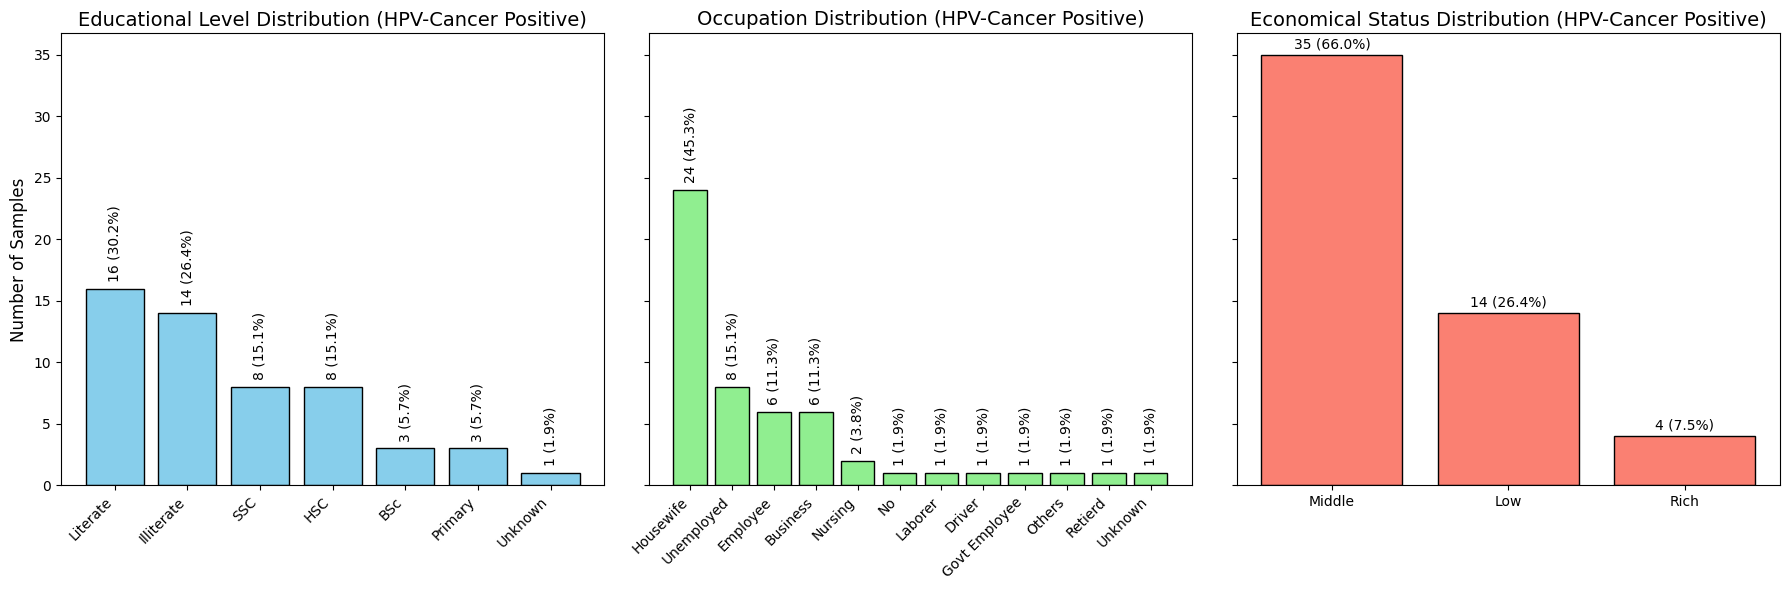

Plot saved as PNG: /content/drive/MyDrive/SV_Thesis/Code/HPV/Education_Occupation_Economical_Distribution_HPV_and_Cancer_Positive.png


In [ ]:
# Filter for cancer-positive samples
positive_samples = data[data['Carcinoma Status'] == 'Positive']

# Select columns for Education, Occupation, and Economical Status
education_counts = positive_samples['Educational Level'].value_counts()
occupation_counts = positive_samples['Occupation'].value_counts()
economical_counts = positive_samples['Economical Status'].value_counts()

# Calculate percentages
education_percentages = (education_counts / education_counts.sum()) * 100
occupation_percentages = (occupation_counts / occupation_counts.sum()) * 100
economical_percentages = (economical_counts / economical_counts.sum()) * 100

# Create the merged figure with space adjustment for bar top labels
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

# Education Bar Plot
axes[0].bar(education_counts.index, education_counts, color='skyblue', edgecolor='black')
for i, (count, pct) in enumerate(zip(education_counts, education_percentages)):
    axes[0].text(i, count + 0.8, f"{count} ({pct:.1f}%)", ha='center', fontsize=10, rotation=90)
axes[0].set_title('Educational Level Distribution (HPV-Cancer Positive)', fontsize=14)
axes[0].set_ylabel('Number of Samples', fontsize=12)
axes[0].set_xticks(range(len(education_counts.index)))
axes[0].set_xticklabels(education_counts.index, rotation=45, ha='right')

# Occupation Bar Plot
axes[1].bar(occupation_counts.index, occupation_counts, color='lightgreen', edgecolor='black')
for i, (count, pct) in enumerate(zip(occupation_counts, occupation_percentages)):
    axes[1].text(i, count + 0.8, f"{count} ({pct:.1f}%)", ha='center', fontsize=10, rotation=90)
axes[1].set_title('Occupation Distribution (HPV-Cancer Positive)', fontsize=14)
axes[1].set_xticks(range(len(occupation_counts.index)))
axes[1].set_xticklabels(occupation_counts.index, rotation=45, ha='right')

# Economical Status Bar Plot
axes[2].bar(economical_counts.index, economical_counts, color='salmon', edgecolor='black')
for i, (count, pct) in enumerate(zip(economical_counts, economical_percentages)):
    axes[2].text(i, count + 0.5, f"{count} ({pct:.1f}%)", ha='center', fontsize=10)
axes[2].set_title('Economical Status Distribution (HPV-Cancer Positive)', fontsize=14)
axes[2].set_xticks(range(len(economical_counts.index)))
axes[2].set_xticklabels(economical_counts.index)

# Adjust layout
plt.tight_layout()

# Save the figure as a PNG file
output_file = '/content/drive/MyDrive/SV_Thesis/Code/HPV/Education_Occupation_Economical_Distribution_HPV_and_Cancer_Positive.png'
plt.savefig(output_file, format='png', dpi=600)
plt.show()

print(f"Plot saved as PNG: {output_file}")


In [ ]:
!pip install upsetplot


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for upsetplot: filename=UpSetPlot-0.9.0-py3-none-any.whl size=24819 sha256=471c1d15a4b4bf9a0dc5e7e63c327a591b23daffcd704d43388a258f502c897c
  Stored in directory: /root/.cache/pip/wheels/73/42/9f/1c9718ea27f30466d2787e0f7d88a7cb11942e3460c17e0ef6
Successfully built upsetplot


<ipython-input-20-45c24393159c>:21: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  addiction_memberships = addiction_data.applymap(lambda x: x == 'Yes').astype(bool)
/usr/local/lib/python3.10/dist-packages/upsetplot/data.py:303: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/usr/local/lib/python3.10/dist-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using '

<Figure size 1200x600 with 0 Axes>

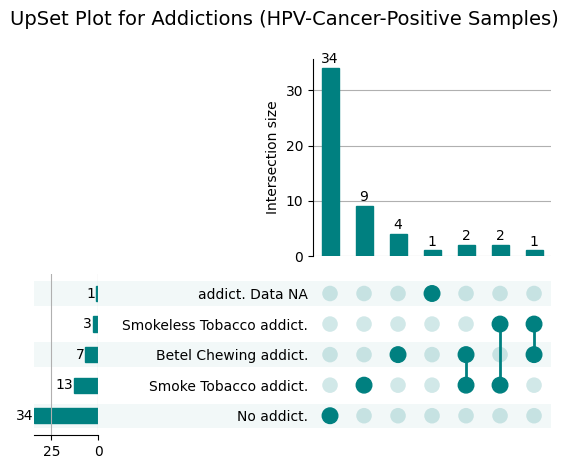

UpSet plot saved as PNG: /content/drive/MyDrive/SV_Thesis/Code/HPV/Addictions_UpSet_Plot_Positive_Samples.png


In [ ]:
import matplotlib.pyplot as plt
from upsetplot import UpSet, from_memberships

# Filter for cancer-positive samples
positive_samples = data[data['Carcinoma Status'] == 'Positive']

# Select addiction columns
addiction_columns = [
    'Betel Chewing addict.',
    'Smokeless Tobacco addict.',
    'Smoke Tobacco addict.',
    'Alcohol addict.',
    'No addict.',
    'addict. Data NA'
]

# Create a DataFrame of boolean values for the addiction columns
addiction_data = positive_samples[addiction_columns]

# Convert the addiction data into a binary representation for an UpSet plot
addiction_memberships = addiction_data.applymap(lambda x: x == 'Yes').astype(bool)
addiction_combinations = from_memberships(
    addiction_memberships.apply(lambda row: tuple(row[row].index), axis=1)
)

# Calculate percentages for the plot
addiction_combinations *= 100 / len(positive_samples)

# Create the UpSet plot
plt.figure(figsize=(12, 6))
upset = UpSet(
    addiction_combinations,
    show_counts=True,
    subset_size='count',
    sort_by='degree',
    facecolor="teal"  # Add color to bars
)
upset.plot()
plt.suptitle('UpSet Plot for Addictions (HPV-Cancer-Positive Samples)', fontsize=14)
plt.tight_layout()

# Save the plot
output_file = '/content/drive/MyDrive/SV_Thesis/Code/HPV/Addictions_UpSet_Plot_Positive_Samples.png'
plt.savefig(output_file, format='png', dpi=300)
plt.show()

print(f"UpSet plot saved as PNG: {output_file}")


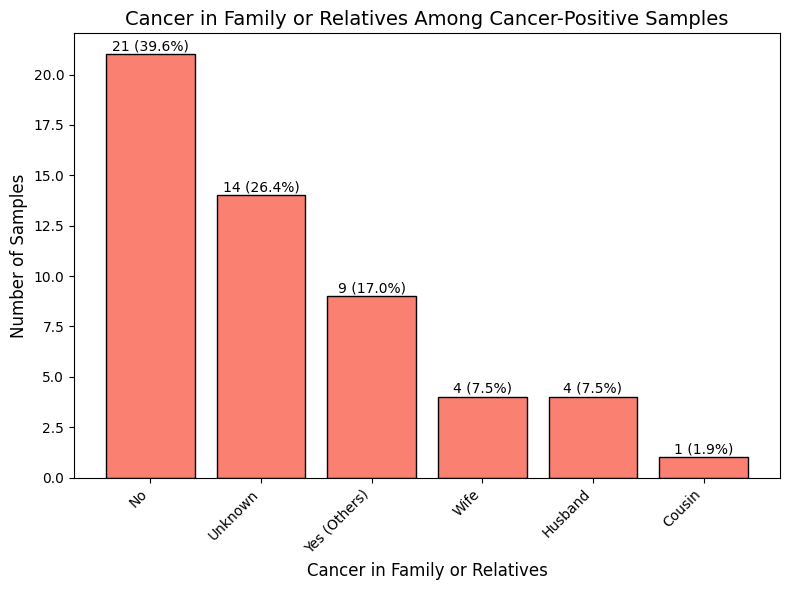

In [ ]:
# Filter for cancer-positive samples
positive_samples = data[data['Carcinoma Status'] == 'Positive']

# Count family status values
family_status_counts = positive_samples['Cancer in Family or Relative'].value_counts()

# Calculate percentages
family_status_percentages = (family_status_counts / family_status_counts.sum()) * 100

# Create the bar plot
plt.figure(figsize=(8, 6))
bars = plt.bar(
    family_status_counts.index,
    family_status_counts,
    color='salmon',
    edgecolor='black'
)

# Add text annotations for count and percentage
for bar, count, pct in zip(bars, family_status_counts, family_status_percentages):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + .2,
        f"{count} ({pct:.1f}%)",
        ha='center',
        fontsize=10
    )

# Add title and labels
plt.title('Cancer in Family or Relatives Among Cancer-Positive Samples', fontsize=14)
plt.xlabel('Cancer in Family or Relatives', fontsize=12)
plt.ylabel('Number of Samples', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Adjust layout and show the plot
plt.tight_layout()
plt.show()

In [ ]:
# Save the bar plot as a PNG file with 600 dpi
output_file = '/content/drive/MyDrive/SV_Thesis/Code/HPV/Family_Status_Cancer_Positive_Samples.png'

plt.figure(figsize=(8, 6))
bars = plt.bar(
    family_status_counts.index,
    family_status_counts,
    color='salmon',
    edgecolor='black'
)

# Add text annotations for count and percentage
for bar, count, pct in zip(bars, family_status_counts, family_status_percentages):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + .2,
        f"{count} ({pct:.1f}%)",
        ha='center',
        fontsize=10
    )

# Add title and labels
plt.title('Cancer in Family or Relatives Among HPV-Cancer-Positive Samples', fontsize=14)
plt.xlabel('Cancer in Family or Relatives', fontsize=12)
plt.ylabel('Number of Samples', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Adjust layout and save the plot
plt.tight_layout()
plt.savefig(output_file, format='png', dpi=600)
plt.close()

print(f"Bar plot saved as PNG file: {output_file}")


Bar plot saved as PNG file: /content/drive/MyDrive/SV_Thesis/Code/HPV/Family_Status_Cancer_Positive_Samples.png


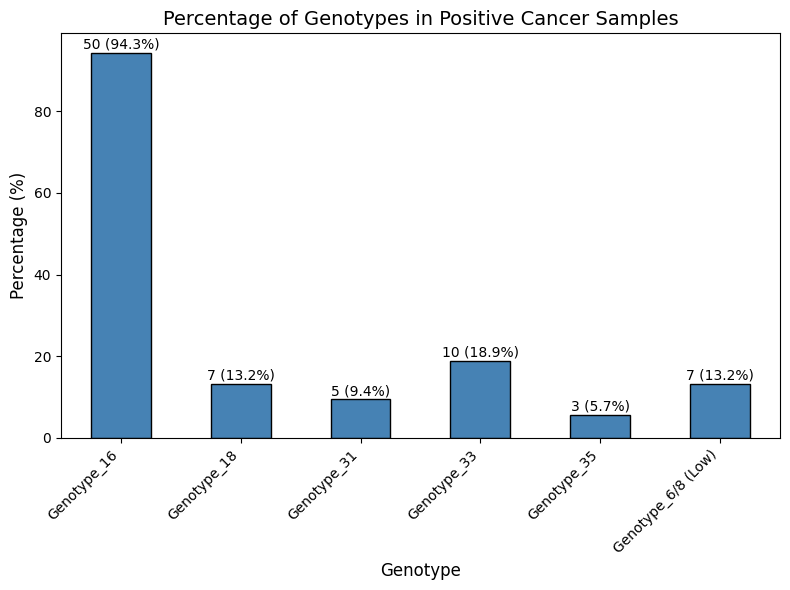

In [ ]:
# Calculate the percentage of 'Yes' responses for each genotype in the positive cancer samples
genotype_positive_cancer_percentage = (positive_samples[genotype_columns].apply(lambda x: (x == 'Yes').sum(), axis=0) / len(positive_samples)) * 100


# Reduce font size inside the plot for better clarity
plt.figure(figsize=(8, 6))
ax = genotype_positive_cancer_percentage.plot(kind='bar', color='steelblue', edgecolor='black')

# Add titles and labels with reduced font size
plt.title('Percentage of Genotypes in Positive Cancer Samples', fontsize=14)
plt.xlabel('Genotype', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)


# Add count and percentage labels above the bars with reduced font size
for i, v in enumerate(genotype_positive_cancer_percentage):
    count = (positive_samples[genotype_columns[i]] == 'Yes').sum()
    ax.text(i, v + 1, f'{count} ({v:.1f}%)', ha='center', fontsize=10)

# Show the plot
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/SV_Thesis/Code/HPV/genotype_percentage_with_counts_small_font.png')
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: '/mnt/data/venn_genotypes.png'

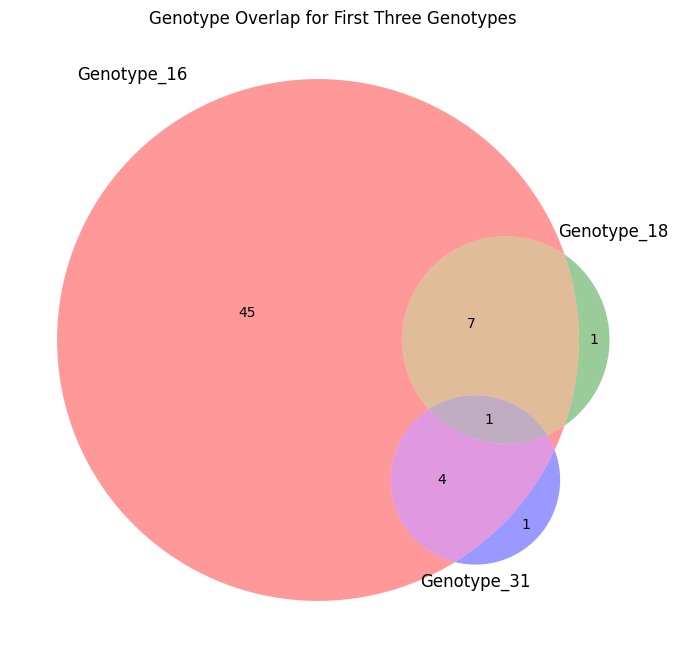

In [ ]:
# Create an alternative for the UpSet plot using Venn diagrams if possible.
from matplotlib_venn import venn3, venn3_circles
import matplotlib.pyplot as plt
import itertools

# Select genotype columns
genotype_columns = ['Genotype_16', 'Genotype_18', 'Genotype_31', 'Genotype_33', 'Genotype_35', 'Genotype_6/8 (Low)']

# Create combinations of sets for visualization (up to 3 genotypes for Venn compatibility)
data_sets = {col: set(data.index[data[col] == 'Yes']) for col in genotype_columns}
all_combinations = list(itertools.combinations(genotype_columns, 3))[:1]  # Limit to the first 3-genotype combo for simplicity

# Plot the Venn diagram for the first combination
plt.figure(figsize=(10, 8))
venn_data = {key: data_sets[key] for key in all_combinations[0]}
venn3([venn_data[col] for col in all_combinations[0]], set_labels=all_combinations[0])
plt.title("Genotype Overlap for First Three Genotypes")

# Save and show plot
plt.savefig('/mnt/data/venn_genotypes.png')
plt.show()


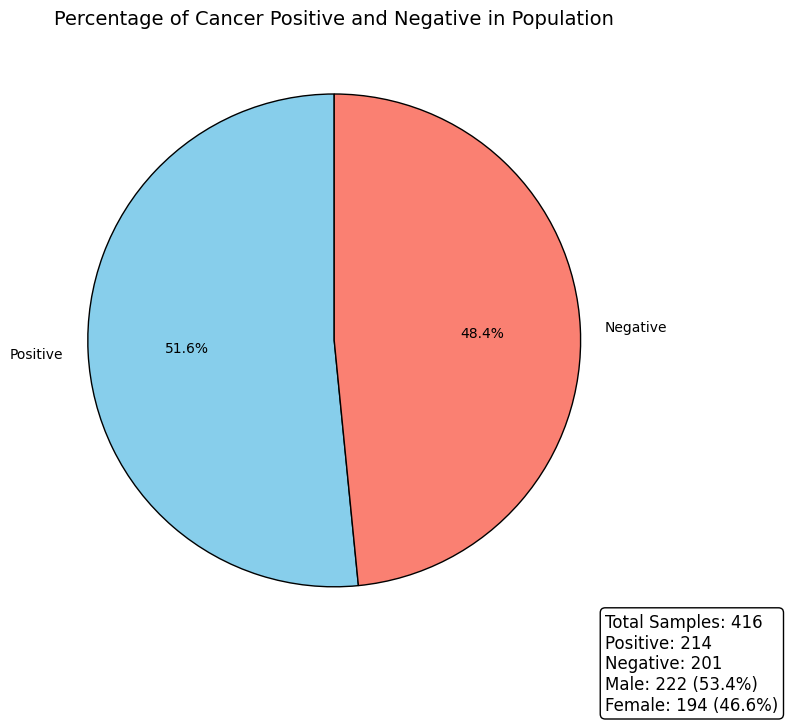

In [ ]:
# Calculate gender distribution
gender_counts = data['Gender'].value_counts()
gender_percentages = data['Gender'].value_counts(normalize=True) * 100

# Extract male and female counts and percentages
male_count = gender_counts.get('M', 0)
female_count = gender_counts.get('F', 0)
male_percentage = gender_percentages.get('M', 0)
female_percentage = gender_percentages.get('F', 0)

# Plot a pie chart for carcinoma status percentages
plt.figure(figsize=(8, 8))
carcinoma_status_counts.plot(
    kind='pie',
    autopct='%1.1f%%',
    colors=['skyblue', 'salmon'],
    startangle=90,
    wedgeprops={'edgecolor': 'black', 'linewidth': 1}
)
plt.title('Percentage of Cancer Positive and Negative in Population', fontsize=14)
plt.ylabel('')  # Remove y-label for better appearance

# Add total sample count, positive/negative counts, and male/female details in the corner
plt.text(
    1.1, -1.5,  # Position slightly outside the plot
    f"Total Samples: {total_samples}\n"
    f"Positive: {positive_samples_count}\n"
    f"Negative: {negative_samples_count}\n"
    f"Male: {male_count} ({male_percentage:.1f}%)\n"
    f"Female: {female_count} ({female_percentage:.1f}%)",
    fontsize=12,
    color='black',
    bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3')
)

plt.show()


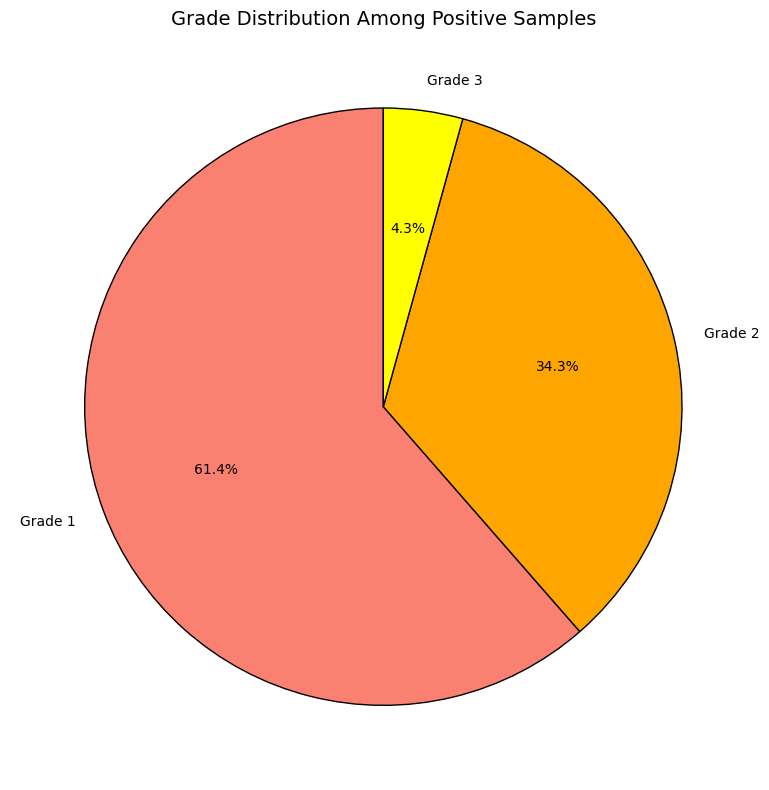

In [ ]:
# Calculate the grade distribution for positive samples
positive_grade_distribution = positive_samples['Grade'].value_counts(normalize=True) * 100

# Plot pie chart for grade distribution among positive samples
plt.figure(figsize=(8, 8))
positive_grade_distribution.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    colors=['salmon', 'orange', 'yellow'],
    wedgeprops={'edgecolor': 'black', 'linewidth': 1},
    labels=[f'Grade {int(grade)}' for grade in positive_grade_distribution.index]
)

# Title and layout adjustments
plt.title('Grade Distribution Among Positive Samples', fontsize=14)
plt.ylabel('')  # Remove y-label for better appearance
plt.tight_layout()
plt.show()


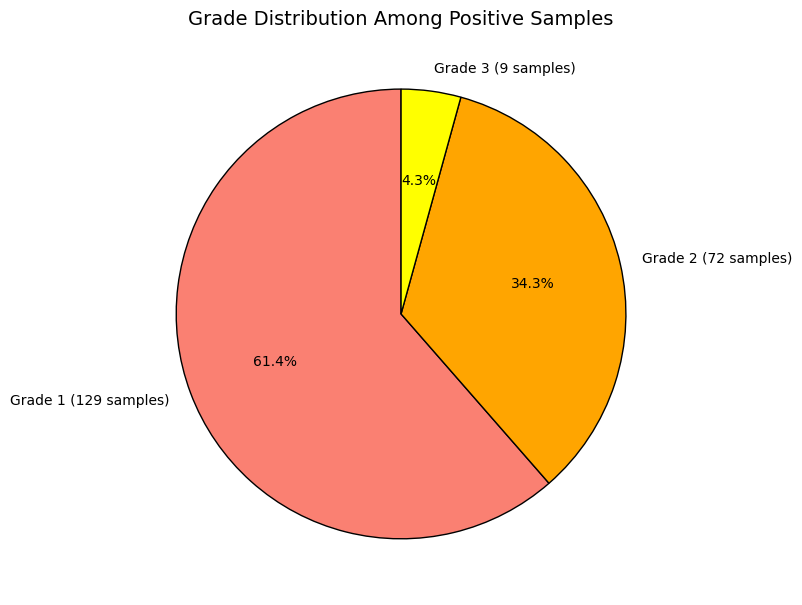

In [ ]:
# Calculate the absolute counts for positive grades
positive_grade_counts = positive_samples['Grade'].value_counts()

# Create labels with grade numbers and counts
labels = [
    f'Grade {int(grade)} ({count} samples)'
    for grade, count in zip(positive_grade_counts.index, positive_grade_counts.values)
]

# Plot pie chart for grade distribution among positive samples with enhanced legend
plt.figure(figsize=(8, 8))
positive_grade_distribution.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    colors=['salmon', 'orange', 'yellow'],
    wedgeprops={'edgecolor': 'black', 'linewidth': 1},
    labels=labels
)

# Title and layout adjustments
plt.title('Grade Distribution Among Positive Samples', fontsize=14)
plt.ylabel('')  # Remove y-label for better appearance
plt.tight_layout()
plt.show()


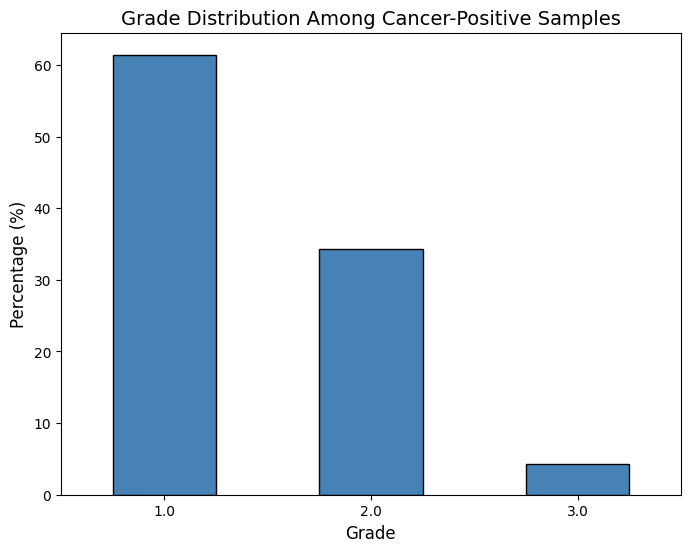

In [ ]:
# Re-importing necessary libraries and reloading the data due to environment reset
import pandas as pd
import matplotlib.pyplot as plt

# Filter the data to include only positive carcinoma samples
positive_samples = data[data['Carcinoma Status'] == 'Positive']

# Calculate the grade distribution among positive samples
grade_distribution = positive_samples['Grade'].value_counts(normalize=True) * 100

# Plot the grade distribution
plt.figure(figsize=(8, 6))
grade_distribution.sort_index().plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Grade Distribution Among Cancer-Positive Samples', fontsize=14)
plt.xlabel('Grade', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.xticks(rotation=0, fontsize=10)

plt.show()


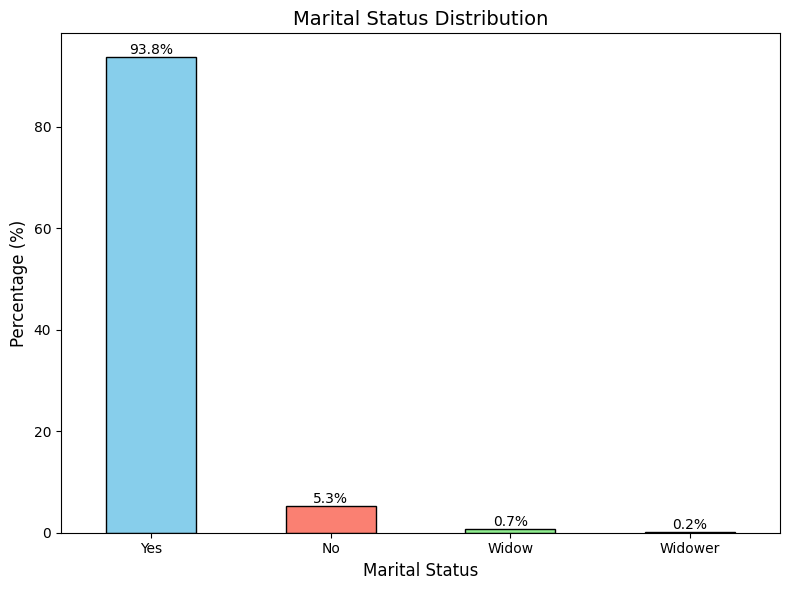

In [ ]:
# Calculate marital status distribution
marital_status_distribution = data['Marital Status'].value_counts(normalize=True) * 100


# Plot marital status distribution with numbers above the bars
plt.figure(figsize=(8, 6))
ax = marital_status_distribution.plot(
    kind='bar',
    color=['skyblue', 'salmon', 'lightgreen', 'lightgray'],
    edgecolor='black'
)

# Add numbers above the bars
for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.1f}%',
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha='center',
        va='bottom',
        fontsize=10
    )

# Title and labels
plt.title('Marital Status Distribution', fontsize=14)
plt.xlabel('Marital Status', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.xticks(rotation=0, fontsize=10)

plt.tight_layout()
plt.show()


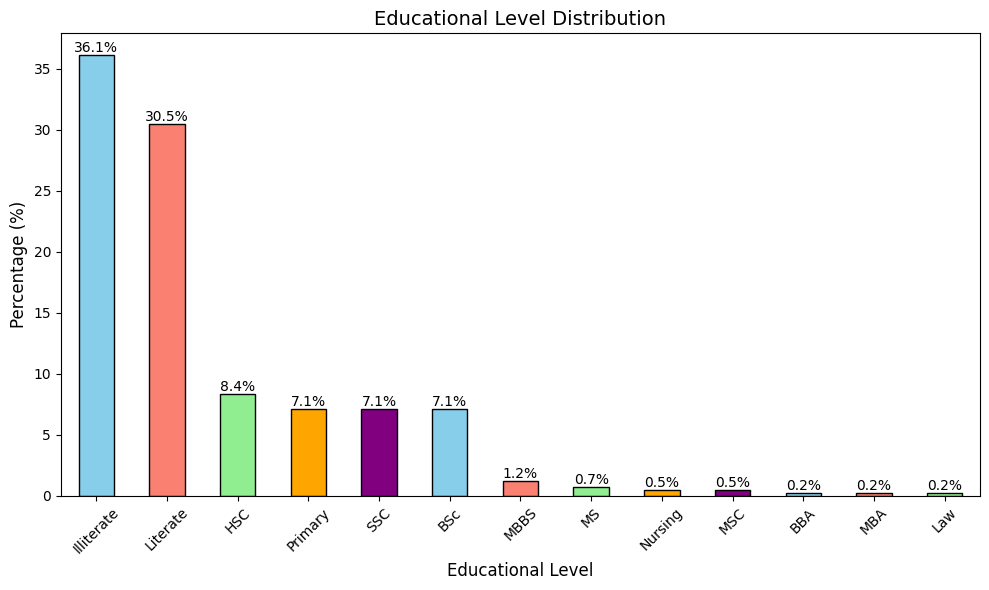

In [ ]:
# Calculate the educational status distribution
educational_status_distribution = data['Educational Level'].value_counts(normalize=True) * 100

# Plot educational status distribution
plt.figure(figsize=(10, 6))
ax = educational_status_distribution.plot(
    kind='bar',
    color=['skyblue', 'salmon', 'lightgreen', 'orange', 'purple'],
    edgecolor='black'
)

# Add numbers above the bars
for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.1f}%',
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha='center',
        va='bottom',
        fontsize=10
    )

# Title and labels
plt.title('Educational Level Distribution', fontsize=14)
plt.xlabel('Educational Level', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.xticks(rotation=45, fontsize=10)

plt.tight_layout()
plt.show()


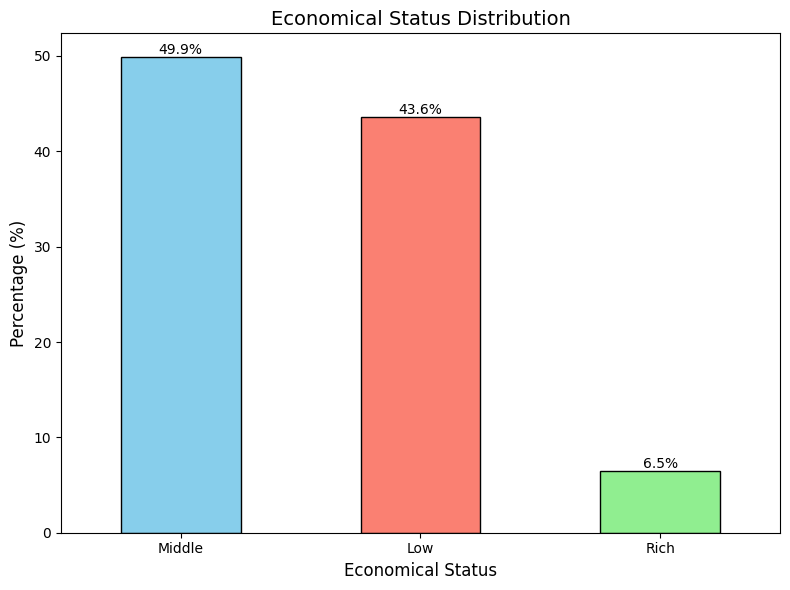

In [ ]:
# Calculate the economical status distribution
economical_status_distribution = data['Economical Status'].value_counts(normalize=True) * 100

# Plot economical status distribution
plt.figure(figsize=(8, 6))
ax = economical_status_distribution.plot(
    kind='bar',
    color=['skyblue', 'salmon', 'lightgreen'],
    edgecolor='black'
)

# Add numbers above the bars
for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.1f}%',
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha='center',
        va='bottom',
        fontsize=10
    )

# Title and labels
plt.title('Economical Status Distribution', fontsize=14)
plt.xlabel('Economical Status', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.xticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()


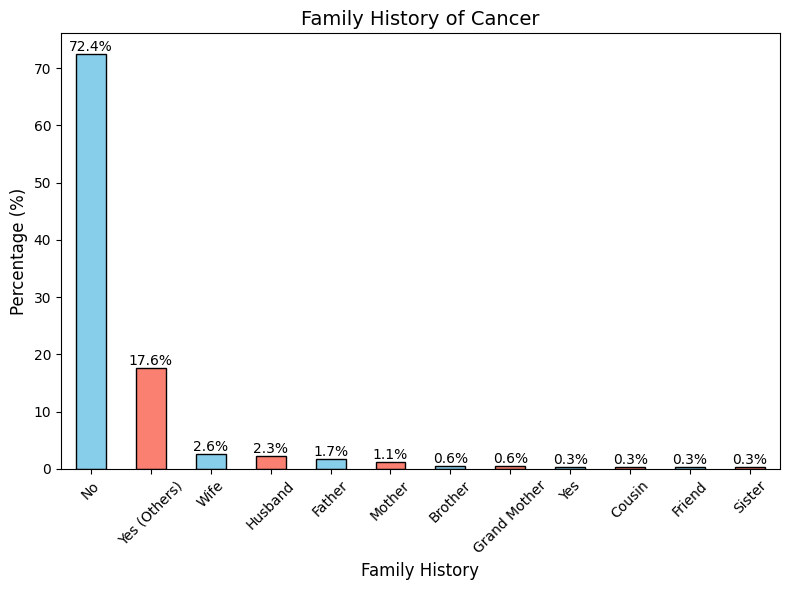

In [ ]:
# Calculate family history distribution
family_history_distribution = data['Cancer in Family or Relatives'].value_counts(normalize=True) * 100

# Plot family history distribution
plt.figure(figsize=(8, 6))
ax1 = family_history_distribution.plot(
    kind='bar',
    color=['skyblue', 'salmon'],
    edgecolor='black'
)
for p in ax1.patches:
    ax1.annotate(
        f'{p.get_height():.1f}%',
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha='center',
        va='bottom',
        fontsize=10
    )
plt.title('Family History of Cancer', fontsize=14)
plt.xlabel('Family History', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.xticks(rotation=45, fontsize=10)
plt.tight_layout()
plt.show()

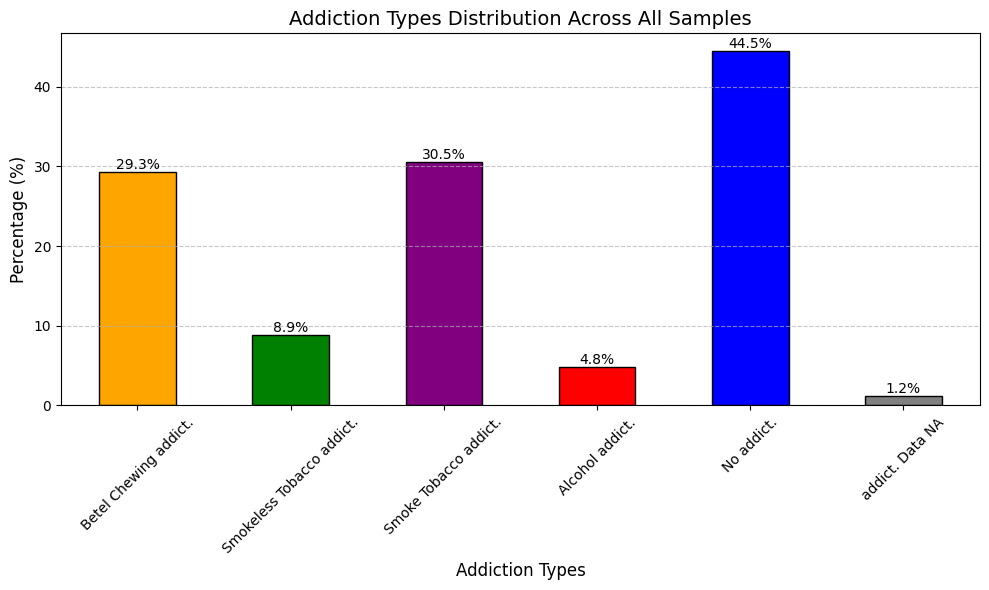

In [ ]:
# Combine addiction-related columns into a single DataFrame
addiction_columns = [
    'Betel Chewing addict.',
    'Smokeless Tobacco addict.',
    'Smoke Tobacco addict.',
    'Alcohol addict.',
    'No addict.',
    'addict. Data NA'
]

# Calculate the percentage of "Yes" responses for each addiction type
addiction_distribution = data[addiction_columns].apply(lambda x: (x == 'Yes').sum()) / len(data) * 100

# Plot the addiction distribution
plt.figure(figsize=(10, 6))
ax = addiction_distribution.plot(
    kind='bar',
    color=['orange', 'green', 'purple', 'red', 'blue', 'gray'],
    edgecolor='black'
)

# Add numbers above the bars
for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.1f}%',
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha='center',
        va='bottom',
        fontsize=10
    )

# Title and labels
plt.title('Addiction Types Distribution Across All Samples', fontsize=14)
plt.xlabel('Addiction Types', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.xticks(rotation=45, fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


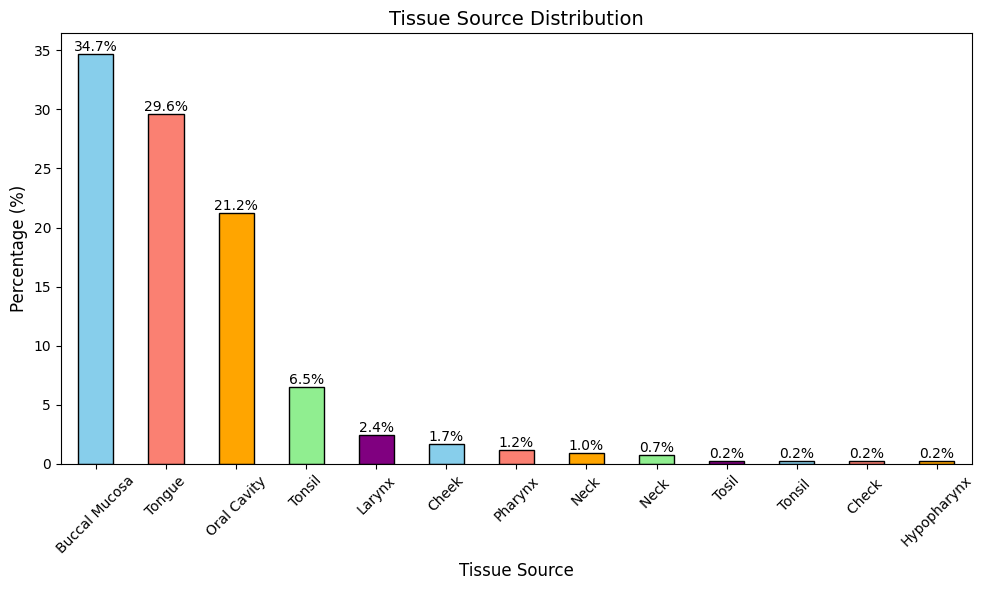

In [ ]:
# Calculate tissue source distribution
tissue_source_distribution = data['Tissue Source'].value_counts(normalize=True) * 100

# Plot tissue source distribution
plt.figure(figsize=(10, 6))
ax = tissue_source_distribution.plot(
    kind='bar',
    color=['skyblue', 'salmon', 'orange', 'lightgreen', 'purple'],
    edgecolor='black'
)

# Add numbers above the bars
for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.1f}%',
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha='center',
        va='bottom',
        fontsize=10
    )

# Title and labels
plt.title('Tissue Source Distribution', fontsize=14)
plt.xlabel('Tissue Source', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.xticks(rotation=45, fontsize=10)
plt.tight_layout()
plt.show()


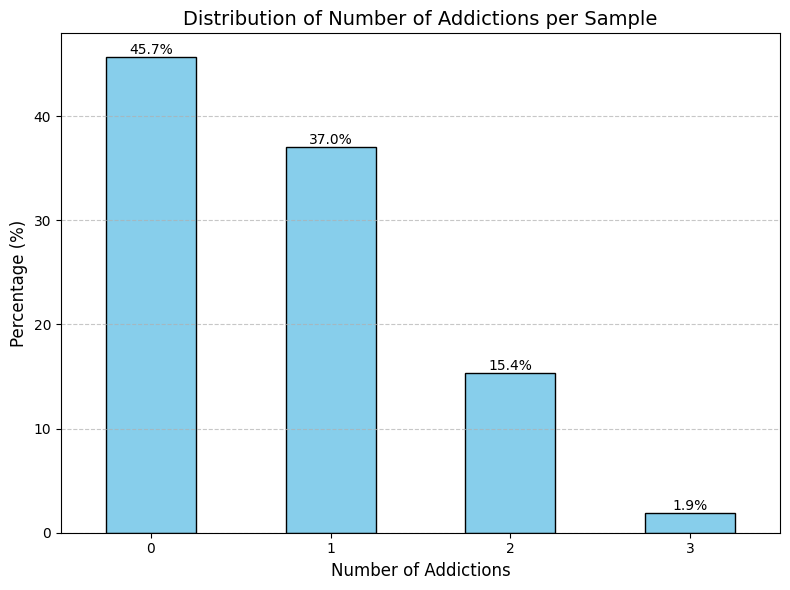

In [ ]:
# Create a new column to count the number of addictions per sample
addiction_columns = [
    'Betel Chewing addict.',
    'Smokeless Tobacco addict.',
    'Smoke Tobacco addict.',
    'Alcohol addict.'
]

# Count the number of "Yes" values in the addiction columns for each sample
data['Number of Addictions'] = data[addiction_columns].apply(lambda x: (x == 'Yes').sum(), axis=1)

# Calculate the distribution of the number of addictions
addiction_count_distribution = data['Number of Addictions'].value_counts(normalize=True) * 100

# Plot the distribution of the number of addictions per sample
plt.figure(figsize=(8, 6))
ax = addiction_count_distribution.sort_index().plot(
    kind='bar',
    color='skyblue',
    edgecolor='black'
)

# Add numbers above the bars
for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.1f}%',
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha='center',
        va='bottom',
        fontsize=10
    )

# Title and labels
plt.title('Distribution of Number of Addictions per Sample', fontsize=14)
plt.xlabel('Number of Addictions', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.xticks(rotation=0, fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
